A dense network sees a fixed-size input and has no notion of "before". A convolution sees
a fixed window. Neither can answer *"has this pattern been building up for the last two
seconds?"* &mdash; and for EEG, speech, or text, that is usually the question.

A recurrent network adds one thing: a **hidden state carried from one timestep to the
next**.

$$\mathbf{h}_t = \tanh\big(W_x\mathbf{x}_t + W_h\mathbf{h}_{t-1} + \mathbf{b}\big)$$

That is the entire architecture. $\mathbf{h}_t$ is a summary of everything seen so far,
$\mathbf{h}_{t-1}$ carries it forward, and the *same* weights are used at every timestep &mdash;
parameter sharing across **time** rather than across space.

It also has a specific, famous failure. Because the same $W_h$ is applied at every step,
gradients flowing back through $T$ steps are multiplied by $W_h$ roughly $T$ times, so
they **vanish or explode geometrically**. That failure is measured below, and it is
exactly what the LSTM was invented to fix.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


In [2]:
def draw_network(layer_sizes, Ws, bs, title="", node_values=None,
                 layer_names=None, node_labels=None, show_weights=True,
                 ax=None, wmax=None, figsize=None, fontsize=8):
    """Draw a feed-forward network with its weights written on the edges.

    layer_sizes : e.g. [2, 4, 1]
    Ws, bs      : lists of weight matrices / bias vectors
    node_values : optional list of per-layer arrays to print inside the nodes
    """
    L = len(layer_sizes)
    own = ax is None
    if own:
        figsize = figsize or (3.0 * L + 3.0, 1.75 * max(layer_sizes) + 2.0)
        fig, ax = plt.subplots(figsize=figsize)

    # vertical positions, each layer centred on 0. VSPACE must leave room for
    # the node label above each circle (radius .42), or labels collide.
    VSPACE = 1.6
    pos = []
    for li, nsz in enumerate(layer_sizes):
        ys = np.linspace(-(nsz - 1) / 2.0, (nsz - 1) / 2.0, nsz) * VSPACE
        pos.append([(li * 3.0, yy) for yy in ys])

    if wmax is None:
        wmax = max(np.abs(W).max() for W in Ws) if Ws else 1.0
    wmax = max(wmax, 1e-9)

    for li, W in enumerate(Ws):
        for a in range(W.shape[0]):
            for b in range(W.shape[1]):
                wv = W[a, b]
                x0, y0 = pos[li][a]
                x1, y1 = pos[li + 1][b]
                lw = 0.4 + 4.6 * abs(wv) / wmax
                col = "#1d4ed8" if wv >= 0 else "#b91c1c"
                ax.plot([x0 + .42, x1 - .42], [y0, y1], color=col, lw=lw,
                        alpha=.75, zorder=1, solid_capstyle="round")
                if show_weights:
                    t = 0.5
                    ax.text(x0 + .42 + t * (x1 - x0 - .84), y0 + t * (y1 - y0),
                            f"{wv:+.2f}", fontsize=fontsize - 1.4, color=col,
                            ha="center", va="center", zorder=4,
                            bbox=dict(boxstyle="round,pad=0.10", fc="white",
                                      ec="none", alpha=.82))

    for li, nsz in enumerate(layer_sizes):
        for a in range(nsz):
            x, yy = pos[li][a]
            face = "#e0e7ff" if li == 0 else ("#dcfce7" if li == L - 1 else "#fef3c7")
            ax.add_patch(plt.Circle((x, yy), .42, fc=face, ec="#334155",
                                    lw=1.5, zorder=3))
            inner = ""
            if node_values is not None and node_values[li] is not None:
                inner = f"{node_values[li][a]:+.2f}"
            elif li > 0 and bs and bs[li - 1] is not None:
                inner = f"b{bs[li-1].ravel()[a]:+.2f}"
            if inner:
                ax.text(x, yy, inner, ha="center", va="center",
                        fontsize=fontsize - 1, zorder=5, family="monospace")
            if node_labels and node_labels[li]:
                lab = str(node_labels[li][a])
                if li == 0:                      # inputs: label to the left
                    ax.text(x - .55, yy, lab, ha="right", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                elif li == L - 1:                # output: label to the right
                    ax.text(x + .55, yy, lab, ha="left", va="center",
                            fontsize=fontsize - .5, color="#334155", zorder=5)
                else:                            # hidden: above, in the gap
                    ax.text(x, yy + .52, lab, ha="center", va="bottom",
                            fontsize=fontsize - .5, color="#334155", zorder=5)

    if layer_names:
        top = max(max(abs(p[1]) for p in lay) for lay in pos) + 1.25
        for li, nm in enumerate(layer_names):
            ax.text(li * 3.0, top, nm, ha="center", va="bottom",
                    fontsize=fontsize + 1.2, fontweight="bold", color="#1e293b")

    allx = [p[0] for lay in pos for p in lay]
    ally = [p[1] for lay in pos for p in lay]
    ax.set_xlim(min(allx) - 1.0, max(allx) + 1.0)
    ax.set_ylim(min(ally) - 1.1, max(ally) + 2.1)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=11, fontweight="bold", pad=10)
    if own:
        plt.tight_layout(); plt.show()
    return ax


print("Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).")
print("   edge width = |weight|,  blue = positive,  red = negative")

Network diagram helper ready: draw_network(layer_sizes, Ws, bs, ...).
   edge width = |weight|,  blue = positive,  red = negative


---
# 1. The Sequence

A short EEG-like sequence: 6 timesteps, 2 features per step (say band power and line
length). The task is to say whether a seizure is underway by the end &mdash; a decision that
depends on the *history*, not on the final timestep alone.

In [3]:
T, D_IN, D_HID = 6, 2, 3

Xs = np.array([
    [0.20, 0.10],
    [0.25, 0.15],
    [0.30, 0.20],
    [0.90, 0.80],     # something starts here
    [1.10, 0.95],
    [1.20, 1.05],
])
step_names = [f"t{i}" for i in range(T)]
feat_names = ["band_power", "line_length"]
y_target = 1.0                       # a seizure is present by the end

print(f"one sequence: {T} timesteps x {D_IN} features\n")
print(f"{'step':>6}  " + "  ".join(f"{f:>13}" for f in feat_names))
print("-" * 40)
for i in range(T):
    mark = "   <- onset" if i == 3 else ""
    print(f"{step_names[i]:>6}  " + "  ".join(f"{v:>13.2f}" for v in Xs[i]) + mark)
print("-" * 40)
print(f"\ntarget: {y_target:.0f} (seizure)   - a property of the WHOLE sequence")
print(f"\nNote what a plain feed-forward net would have to do: either look at one")
print(f"timestep (losing the history) or flatten all {T} into a {T*D_IN}-long vector,")
print(f"which fixes the length forever and learns each position separately.")

one sequence: 6 timesteps x 2 features

  step     band_power    line_length
----------------------------------------
    t0           0.20           0.10
    t1           0.25           0.15
    t2           0.30           0.20
    t3           0.90           0.80   <- onset
    t4           1.10           0.95
    t5           1.20           1.05
----------------------------------------

target: 1 (seizure)   - a property of the WHOLE sequence

Note what a plain feed-forward net would have to do: either look at one
timestep (losing the history) or flatten all 6 into a 12-long vector,
which fixes the length forever and learns each position separately.


---
# 2. The RNN Cell, Unrolled

The cell is applied once per timestep, always with the same weights:

$$\mathbf{h}_t = \tanh\big(W_x\mathbf{x}_t + W_h\mathbf{h}_{t-1} + \mathbf{b}\big),
\qquad \mathbf{h}_{-1} = \mathbf{0}$$

Drawing it "unrolled" makes the structure obvious: it is a deep network whose depth equals
the sequence length, and whose layers are **forced to share one weight matrix**.

In [4]:
rng = np.random.default_rng(3)
Wx = rng.normal(0, .6, (D_IN, D_HID))
Wh = rng.normal(0, .6, (D_HID, D_HID))
bh = np.zeros(D_HID)
Wy = rng.normal(0, .6, (D_HID, 1))
by = np.zeros(1)

def sigmoid(z):
    return np.where(z >= 0, 1/(1+np.exp(-np.abs(z))),
                    np.exp(-np.abs(z))/(1+np.exp(-np.abs(z))))

print("weights - and there is only ONE set, reused at every timestep\n")
show_matrix(Wx, "Wx  (input -> hidden)", rows=feat_names,
            cols=[f"h{j}" for j in range(D_HID)])
print()
show_matrix(Wh, "Wh  (hidden -> hidden)", rows=[f"h{j}" for j in range(D_HID)],
            cols=[f"h{j}" for j in range(D_HID)])
print(f"\nparameters: Wx {Wx.size} + Wh {Wh.size} + bh {bh.size} + Wy {Wy.size} + by "
      f"{by.size} = {Wx.size+Wh.size+bh.size+Wy.size+by.size}")
print(f"and that count does NOT change if the sequence becomes 1000 steps long.")

h = np.zeros(D_HID)
H = [h.copy()]
print("\n\nunrolling, one timestep at a time")
print("=" * 78)
for t in range(T):
    a = Xs[t] @ Wx
    b_ = h @ Wh
    z = a + b_ + bh
    h_new = np.tanh(z)
    print(f"\n--- t = {t} ---   x_t = {np.round(Xs[t], 3)}")
    print(f"   x_t @ Wx        = {np.round(a, 6)}")
    print(f"   h_prev @ Wh     = {np.round(b_, 6)}      (h_prev = {np.round(h, 4)})")
    print(f"   z = sum + bias  = {np.round(z, 6)}")
    print(f"   h_t = tanh(z)   = {np.round(h_new, 6)}")
    if t == 0:
        print(f"\n   worked element h_0[0]:")
        print(f"      {expand(Xs[0], Wx[:, 0], per_line=2)}")
        print(f"      = {float(Xs[0] @ Wx[:,0]):+.6f}   (h_prev is all zeros, adds nothing)")
        print(f"      tanh({z[0]:+.6f}) = {np.tanh(z[0]):+.6f}   "
              f"MATCH: {np.isclose(np.tanh(z[0]), h_new[0])}")
    h = h_new
    H.append(h.copy())
H = np.array(H)

y_hat = float(sigmoid(h @ Wy + by)[0])
print("\n" + "=" * 78)
print(f"\nfinal hidden state h_{T-1} = {np.round(h, 6)}")
print(f"output = sigmoid(h @ Wy + by) = {y_hat:.6f}   (target {y_target:.0f})")

print(f"\n\nthe hidden state over time - watch it move when the onset arrives\n")
print(f"{'step':>6}  " + "  ".join(f"{'h'+str(j):>11}" for j in range(D_HID)) +
      f"  {'||h||':>9}  {'change':>9}")
print("-" * 62)
for t in range(T+1):
    lbl = "init" if t == 0 else step_names[t-1]
    ch = "" if t == 0 else f"{np.linalg.norm(H[t]-H[t-1]):.4f}"
    print(f"{lbl:>6}  " + "  ".join(f"{H[t,j]:>11.6f}" for j in range(D_HID)) +
          f"  {np.linalg.norm(H[t]):>9.4f}  {ch:>9}")
print("-" * 62)
print(f"\nThe biggest jump is at t3 - the step where the input changed. The state")
print(f"is accumulating a summary, not just reacting to the current input.")

weights - and there is only ONE set, reused at every timestep

Wx  (input -> hidden) (2, 3) =
                     h0        h1        h2
   band_power |   +1.225    -1.533    +0.251
   line_length |   -0.341    -0.272    -0.129

Wh  (hidden -> hidden) (3, 3) =
                     h0        h1        h2
           h0 |   -1.212    -0.139    -0.519
           h1 |   +1.994    +0.135    -0.212
           h2 |   -0.169    -0.401    -0.633

parameters: Wx 6 + Wh 9 + bh 3 + Wy 3 + by 1 = 22
and that count does NOT change if the sequence becomes 1000 steps long.


unrolling, one timestep at a time

--- t = 0 ---   x_t = [0.2 0.1]
   x_t @ Wx        = [ 0.2108 -0.3338  0.0372]
   h_prev @ Wh     = [0. 0. 0.]      (h_prev = [0. 0. 0.])
   z = sum + bias  = [ 0.2108 -0.3338  0.0372]
   h_t = tanh(z)   = [ 0.2078 -0.322   0.0372]

   worked element h_0[0]:
      (+0.2000)*(+1.2246) + (+0.1000)*(-0.3407)
      = +0.210844   (h_prev is all zeros, adds nothing)
      tanh(+0.210844) = +0.207774   

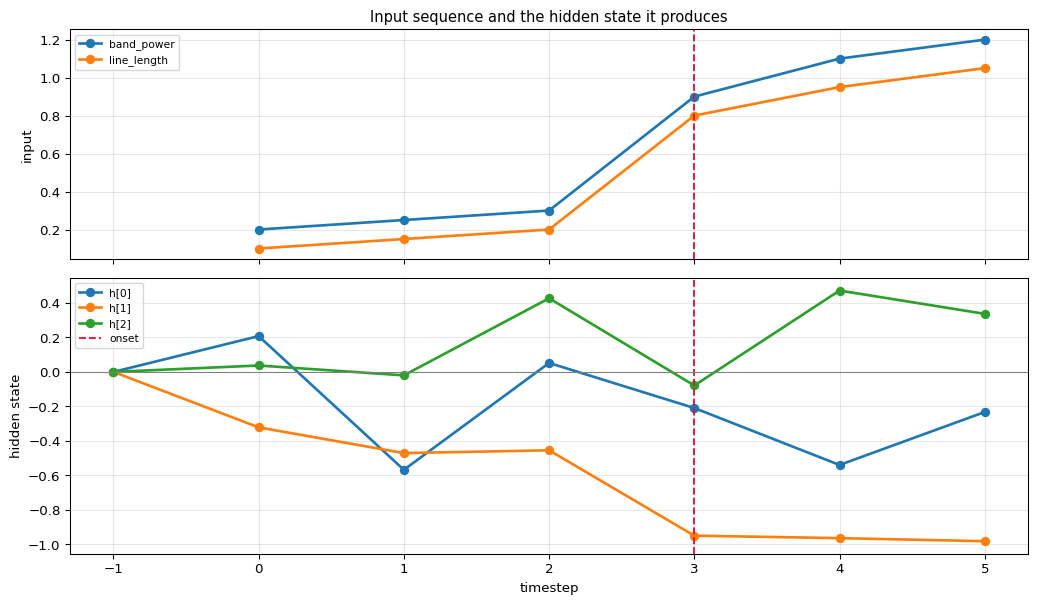

unrolled, the RNN is a deep network with tied weights:



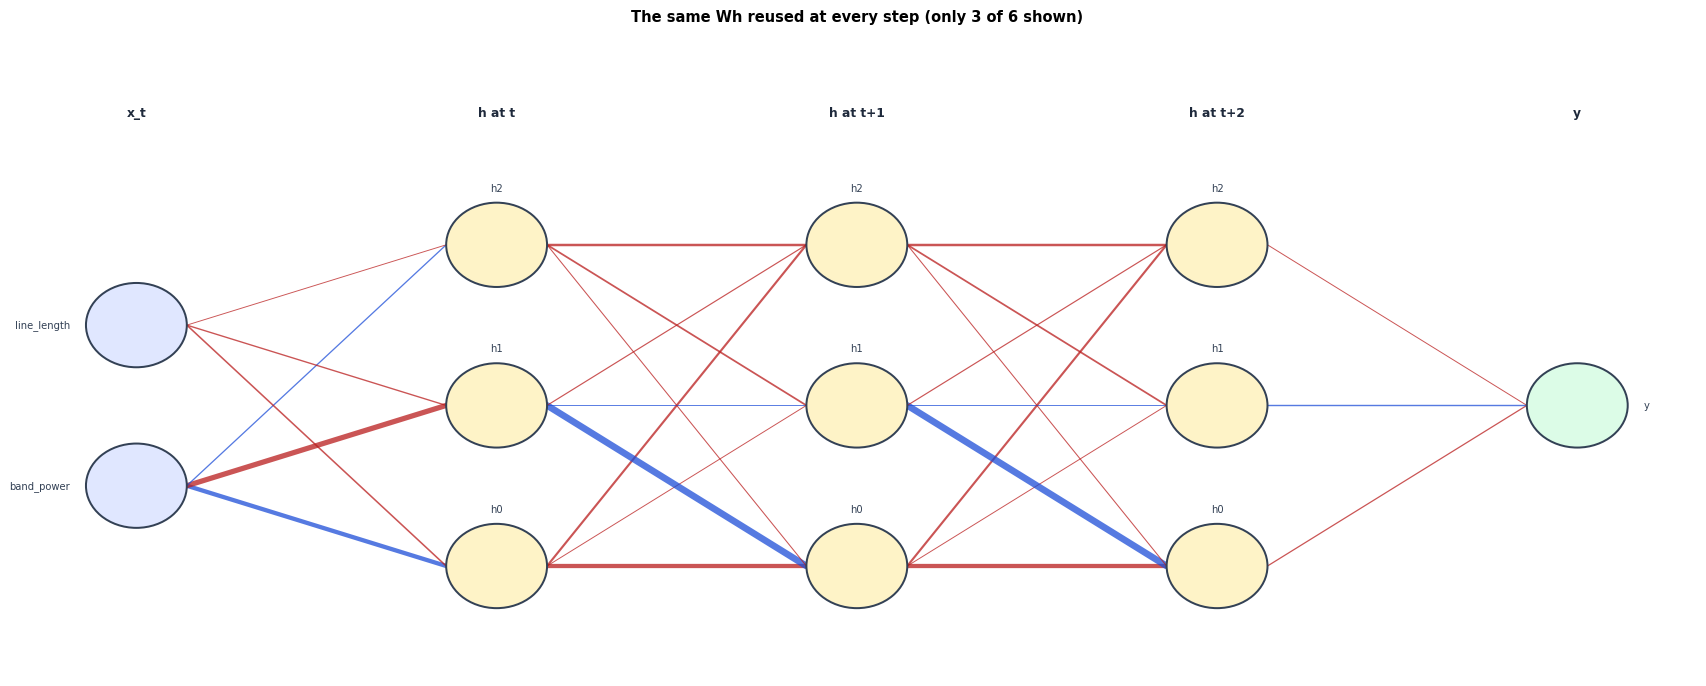

Every hidden-to-hidden arrow above is the SAME matrix Wh. That is what
makes it recurrent - and, as the next section shows, what makes the
gradient behave so badly.


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True,
                         gridspec_kw=dict(height_ratios=[1, 1.2]))
for j, f in enumerate(feat_names):
    axes[0].plot(range(T), Xs[:, j], "o-", lw=2, label=f)
axes[0].axvline(3, color="crimson", ls="--", lw=1.4)
axes[0].set_ylabel("input"); axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)
axes[0].set_title("Input sequence and the hidden state it produces", fontsize=11)
for j in range(D_HID):
    axes[1].plot(range(-1, T), H[:, j], "o-", lw=2, label=f"h[{j}]")
axes[1].axvline(3, color="crimson", ls="--", lw=1.4, label="onset")
axes[1].axhline(0, color="grey", lw=.8)
axes[1].set(xlabel="timestep", ylabel="hidden state")
axes[1].legend(fontsize=8); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("unrolled, the RNN is a deep network with tied weights:\n")
draw_network([D_IN, D_HID, D_HID, D_HID, 1],
             [Wx, Wh, Wh, Wy],
             [None, None, None, None],
             title="The same Wh reused at every step (only 3 of 6 shown)",
             layer_names=["x_t", "h at t", "h at t+1", "h at t+2", "y"],
             node_labels=[feat_names] + [[f"h{j}" for j in range(D_HID)]]*3 + [["y"]],
             show_weights=False)

print("Every hidden-to-hidden arrow above is the SAME matrix Wh. That is what")
print("makes it recurrent - and, as the next section shows, what makes the")
print("gradient behave so badly.")

---
# 3. Backpropagation Through Time

Training an RNN means unrolling it and running ordinary backpropagation over the unrolled
graph &mdash; **BPTT**. One thing is different from a feed-forward net: since $W_h$ is used at
every step, its gradient is the **sum** of the gradients from every step.

$$\frac{\partial\mathcal{L}}{\partial W_h} = \sum_{t=0}^{T-1}\frac{\partial\mathcal{L}}{\partial W_h}\bigg|_{\text{step }t}$$

And the blame at step $t$ arrives from step $t+1$ through $W_h$, scaled by the local tanh
derivative:

$$\delta_t = \big(\delta_{t+1}W_h^\top\big)\odot\big(1 - \mathbf{h}_t^2\big)$$

That recursion is the source of everything that follows.

In [6]:
def rnn_forward(Xseq, Wx_, Wh_, bh_, Wy_, by_):
    h_ = np.zeros(Wh_.shape[0]); hs = [h_.copy()]
    for t in range(len(Xseq)):
        h_ = np.tanh(Xseq[t] @ Wx_ + h_ @ Wh_ + bh_)
        hs.append(h_.copy())
    yh = float(sigmoid(h_ @ Wy_ + by_)[0])
    return np.array(hs), yh

def bce(yh, yv):
    e = 1e-12
    return float(-(yv*np.log(yh+e) + (1-yv)*np.log(1-yh+e)))

def rnn_backward(Xseq, hs, yh, yv, Wx_, Wh_, Wy_):
    gWx = np.zeros_like(Wx_); gWh = np.zeros_like(Wh_)
    gbh = np.zeros(Wh_.shape[0])
    d_out = yh - yv                                   # dL/dz_out
    gWy = hs[-1][:, None] * d_out
    gby = np.array([d_out])
    delta = (Wy_[:, 0] * d_out) * (1 - hs[-1]**2)     # blame at the last hidden
    per_step = []
    for t in reversed(range(len(Xseq))):
        per_step.append(np.linalg.norm(delta))
        gWx += np.outer(Xseq[t], delta)
        gWh += np.outer(hs[t], delta)
        gbh += delta
        if t > 0:
            delta = (delta @ Wh_.T) * (1 - hs[t]**2)
    return gWx, gWh, gbh, gWy, gby, per_step[::-1]

hs, yh = rnn_forward(Xs, Wx, Wh, bh, Wy, by)
L0 = bce(yh, y_target)
gWx, gWh, gbh, gWy, gby, dn = rnn_backward(Xs, hs, yh, y_target, Wx, Wh, Wy)

print(f"forward: y_hat = {yh:.6f}, target = {y_target:.0f}, loss = {L0:.6f}\n")
print(f"blame travelling backwards through time\n")
print(f"{'step':>6}  {'||delta_t||':>13}  {'relative to last step':>23}")
print("-" * 48)
for t in reversed(range(T)):
    print(f"{step_names[t]:>6}  {dn[t]:>13.8f}  {dn[t]/max(dn[-1],1e-15):>22.4%}")
print("-" * 48)
print(f"\nEach step back multiplies by Wh and by (1 - h^2). The tanh derivative is")
print(f"at most 1 and usually well below it, so the blame shrinks as it travels.")
print(f"\n   blame at the last step  : {dn[-1]:.8f}")
print(f"   blame at the first step : {dn[0]:.8f}")
print(f"   ratio                   : {dn[0]/max(dn[-1],1e-15):.6f}")
print(f"\nOver 6 steps that is survivable. Over 100 it is not - see section 4.")

print(f"\n\ngradient check against central differences (all "
      f"{Wx.size+Wh.size+bh.size+Wy.size+by.size} parameters)\n")
EPSG = 1e-6
def loss_now():
    _, yy = rnn_forward(Xs, Wx, Wh, bh, Wy, by)
    return bce(yy, y_target)

worst, checked = 0.0, 0
print(f"{'param':>12}  {'analytic':>15}  {'numerical':>15}  {'rel err':>11}")
print("-" * 58)
for nm, arr, gr in [("Wx", Wx, gWx), ("Wh", Wh, gWh), ("bh", bh, gbh),
                    ("Wy", Wy, gWy), ("by", by, gby)]:
    for idx in np.ndindex(arr.shape):
        o = arr[idx]
        arr[idx] = o + EPSG; lp = loss_now()
        arr[idx] = o - EPSG; lm = loss_now()
        arr[idx] = o
        num = (lp-lm)/(2*EPSG)
        rel = abs(gr[idx]-num)/max(abs(gr[idx])+abs(num), 1e-14)
        worst = max(worst, rel); checked += 1
        if checked <= 6:
            print(f"{f'{nm}{list(idx)}':>12}  {gr[idx]:>15.9f}  {num:>15.9f}  {rel:>11.2e}")
print(f"{'...':>12}")
print("-" * 58)
print(f"\nparameters checked : {checked}")
print(f"worst relative error: {worst:.3e}   -> "
      f"{'CORRECT' if worst < 1e-6 else 'SUSPECT'}")

forward: y_hat = 0.430987, target = 1, loss = 0.841678

blame travelling backwards through time

  step    ||delta_t||    relative to last step
------------------------------------------------
    t5     0.14549277               100.0000%
    t4     0.14433058                99.2012%
    t3     0.18631693               128.0592%
    t2     0.36265026               249.2566%
    t1     0.38179738               262.4167%
    t0     0.35439859               243.5850%
------------------------------------------------

Each step back multiplies by Wh and by (1 - h^2). The tanh derivative is
at most 1 and usually well below it, so the blame shrinks as it travels.

   blame at the last step  : 0.14549277
   blame at the first step : 0.35439859
   ratio                   : 2.435850

Over 6 steps that is survivable. Over 100 it is not - see section 4.


gradient check against central differences (all 22 parameters)

       param         analytic        numerical      rel err
--------------------

---
# 4. Vanishing and Exploding Gradients

The recursion $\delta_t = (\delta_{t+1}W_h^\top)\odot(1-\mathbf{h}_t^2)$ applied $T$ times
means the gradient reaching step 0 has been multiplied by roughly $W_h^T$.

$$\left\lVert\frac{\partial \mathcal{L}}{\partial \mathbf{h}_0}\right\rVert
\;\sim\; \lambda^{T}, \qquad \lambda = \text{largest singular value of } W_h$$

* $\lambda < 1$ &rarr; the gradient **vanishes**: early timesteps receive nothing, so the
  network cannot learn long-range dependencies. It is not slow &mdash; it is *silent*.
* $\lambda > 1$ &rarr; the gradient **explodes**: updates become enormous and training
  destabilises.

The knife-edge at $\lambda = 1$ is why plain RNNs are hard to train beyond ~10&ndash;20 steps.

 top singular value           T=1           T=5          T=10          T=25          T=50
------------------------------------------------------------------------------------
               0.50     2.137e-01     1.616e-03     6.725e-06     8.085e-14     1.405e-26
               0.90     3.847e-01     3.054e-02     2.401e-03     1.947e-07     8.154e-14
               1.00     4.275e-01     5.172e-02     6.886e-03     2.713e-06     1.582e-11
               1.11     4.745e-01     8.715e-02     1.955e-02     3.685e-05     2.920e-09
               1.30     5.557e-01     1.920e-01     9.494e-02     1.914e-03     7.878e-06
------------------------------------------------------------------------------------

our Wh has top singular value 2.3548
   after 6 steps  : ~1.7049e+02
   after 50 steps : ~3.9579e+18
   after 200 steps: ~2.4538e+74


what 'vanishing' means in practice, in float64:

   scale 0.5: gradient reaches 1e-15 at step 29  -> numerically ZERO beyond that
   scale 0.9: gradient r

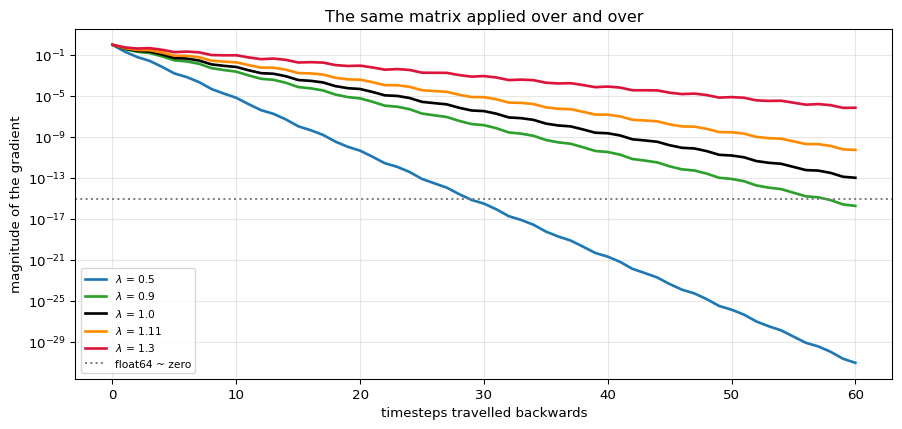

Only the black line (exactly 1.0) is stable, and hitting it exactly is
not something training can be relied on to do. Everything else either
dies or blows up - geometrically.


In [7]:
def blame_decay(scale, steps=60, dim=3, seed=1):
    r = np.random.default_rng(seed)
    M = r.normal(0, 1, (dim, dim))
    M = M / np.linalg.svd(M, compute_uv=False)[0] * scale   # set the top singular value
    d = np.ones(dim) / np.sqrt(dim)
    norms = [np.linalg.norm(d)]
    for _ in range(steps):
        d = d @ M.T * 0.9          # 0.9 stands in for a typical tanh derivative
        norms.append(np.linalg.norm(d))
    return np.array(norms), M

print(f"{'top singular value':>19}  " +
      "  ".join(f"{'T='+str(t):>12}" for t in (1, 5, 10, 25, 50)))
print("-" * 84)
for sc in (0.5, 0.9, 1.0, 1.11, 1.3):
    nn_, _ = blame_decay(sc)
    print(f"{sc:>19.2f}  " + "  ".join(f"{nn_[t]:>12.3e}" for t in (1, 5, 10, 25, 50)))
print("-" * 84)

lam_actual = np.linalg.svd(Wh, compute_uv=False)[0]
print(f"\nour Wh has top singular value {lam_actual:.4f}")
print(f"   after 6 steps  : ~{lam_actual**6:.4e}")
print(f"   after 50 steps : ~{lam_actual**50:.4e}")
print(f"   after 200 steps: ~{lam_actual**200:.4e}")

print(f"\n\nwhat 'vanishing' means in practice, in float64:\n")
for sc in (0.5, 0.9):
    nn_, _ = blame_decay(sc, steps=200)
    below = np.argmax(nn_ < 1e-15) if (nn_ < 1e-15).any() else None
    print(f"   scale {sc}: gradient reaches 1e-15 at step "
          f"{below if below else '>200'}"
          f"{'  -> numerically ZERO beyond that' if below else ''}")
print(f"\n   Beyond that point the early timesteps receive no learning signal at")
print(f"   all. The network is not learning slowly from them; it is not learning")
print(f"   from them.")

fig, ax = plt.subplots(figsize=(9.5, 4.6))
for sc, col in [(0.5, "tab:blue"), (0.9, "tab:green"), (1.0, "k"),
                (1.11, "darkorange"), (1.3, "crimson")]:
    nn_, _ = blame_decay(sc, steps=60)
    ax.plot(nn_, lw=2, color=col, label=f"$\\lambda$ = {sc}")
ax.axhline(1e-15, ls=":", color="grey", label="float64 ~ zero")
ax.set(yscale="log", xlabel="timesteps travelled backwards",
       ylabel="magnitude of the gradient",
       title="The same matrix applied over and over")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Only the black line (exactly 1.0) is stable, and hitting it exactly is")
print("not something training can be relied on to do. Everything else either")
print("dies or blows up - geometrically.")

---
# 5. The LSTM &mdash; a Gradient Highway

The LSTM's answer is not a bigger matrix. It is a **second state**, the cell state
$\mathbf{c}_t$, whose update is **additive** rather than multiplicative:

$$\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} \;+\; \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$$

Compare the two recursions:

$$\text{RNN: } \; \mathbf{h}_t = \tanh(W_h\mathbf{h}_{t-1} + \dots)
\qquad\qquad
\text{LSTM: } \; \mathbf{c}_t = \mathbf{f}_t\odot\mathbf{c}_{t-1} + \dots$$

Going backwards, the RNN multiplies by $W_h$ every step. The LSTM multiplies by
$\mathbf{f}_t$ &mdash; and if the forget gate is near 1, that is multiplying by **one**. The
gradient can travel hundreds of steps essentially unchanged. That is the "constant error
carousel".

Three gates control the flow, each a sigmoid producing values in $(0,1)$:

| Gate | Formula | Question it answers |
|---|---|---|
| **forget** $\mathbf{f}_t$ | $\sigma(W_f[\mathbf{h}_{t-1},\mathbf{x}_t] + b_f)$ | what should I discard? |
| **input** $\mathbf{i}_t$ | $\sigma(W_i[\dots] + b_i)$ | what new is worth storing? |
| **output** $\mathbf{o}_t$ | $\sigma(W_o[\dots] + b_o)$ | what should I expose now? |

with a candidate $\tilde{\mathbf{c}}_t = \tanh(W_c[\dots] + b_c)$ and finally
$\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$.

In [8]:
rng2 = np.random.default_rng(11)
Z = D_IN + D_HID
Wf = rng2.normal(0, .4, (Z, D_HID)); bf = np.ones(D_HID)*1.0    # forget bias = 1
Wi = rng2.normal(0, .4, (Z, D_HID)); bi = np.zeros(D_HID)
Wo = rng2.normal(0, .4, (Z, D_HID)); bo = np.zeros(D_HID)
Wc = rng2.normal(0, .4, (Z, D_HID)); bc = np.zeros(D_HID)

print(f"LSTM parameters: 4 gates x ({Z} x {D_HID} + {D_HID}) = "
      f"{4*(Z*D_HID + D_HID)}")
print(f"plain RNN had  : {Wx.size + Wh.size + bh.size}")
print(f"ratio          : {4*(Z*D_HID+D_HID)/(Wx.size+Wh.size+bh.size):.1f}x more\n")
print(f"the forget-gate bias is initialised to +1 on purpose: sigmoid(1) = "
      f"{float(sigmoid(np.array([1.0]))[0]):.4f},")
print(f"so the gate starts nearly OPEN and the cell state is preserved by default.")

h_l, c_l = np.zeros(D_HID), np.zeros(D_HID)
traces = []
print("\n\nrunning the LSTM, one timestep at a time")
print("=" * 78)
for t in range(T):
    z = np.concatenate([h_l, Xs[t]])
    f_g = sigmoid(z @ Wf + bf)
    i_g = sigmoid(z @ Wi + bi)
    o_g = sigmoid(z @ Wo + bo)
    c_t = np.tanh(z @ Wc + bc)
    c_new = f_g*c_l + i_g*c_t
    h_new = o_g*np.tanh(c_new)
    traces.append(dict(f=f_g, i=i_g, o=o_g, cand=c_t, c=c_new, h=h_new))
    print(f"\n--- t = {t} ---   x_t = {np.round(Xs[t], 3)}")
    print(f"   forget f_t    = {np.round(f_g, 5)}   (1 = keep, 0 = erase)")
    print(f"   input  i_t    = {np.round(i_g, 5)}   (how much of the candidate)")
    print(f"   candidate c~  = {np.round(c_t, 5)}")
    print(f"   output o_t    = {np.round(o_g, 5)}")
    print(f"   c_t = f*c_prev + i*c~")
    print(f"       = {np.round(f_g,4)} * {np.round(c_l,4)} + "
          f"{np.round(i_g,4)} * {np.round(c_t,4)}")
    print(f"       = {np.round(f_g*c_l,5)} + {np.round(i_g*c_t,5)} = {np.round(c_new,5)}")
    print(f"   h_t = o_t * tanh(c_t) = {np.round(h_new, 5)}")
    if t == 0:
        el = 0
        print(f"\n   element 0 of the forget gate, in full:")
        print(f"      z = [h_prev, x_t] = {np.round(z, 4)}")
        print(f"      {expand(z, Wf[:, el], per_line=3)}")
        print(f"      + b = {bf[el]:+.4f}  ->  total {float(z @ Wf[:,el] + bf[el]):+.6f}")
        print(f"      sigmoid({float(z @ Wf[:,el] + bf[el]):+.6f}) = "
              f"{float(sigmoid(np.array([z @ Wf[:,el] + bf[el]]))[0]):.6f}   "
              f"MATCH: {np.isclose(float(sigmoid(np.array([z @ Wf[:,el]+bf[el]]))[0]), f_g[el])}")
    h_l, c_l = h_new, c_new
print("\n" + "=" * 78)

print(f"\ngate activity over time (mean across the {D_HID} units)\n")
print(f"{'step':>6}  {'forget':>9}  {'input':>9}  {'output':>9}  {'||c||':>9}  {'||h||':>9}")
print("-" * 60)
for t in range(T):
    tr = traces[t]
    print(f"{step_names[t]:>6}  {tr['f'].mean():>9.5f}  {tr['i'].mean():>9.5f}  "
          f"{tr['o'].mean():>9.5f}  {np.linalg.norm(tr['c']):>9.5f}  "
          f"{np.linalg.norm(tr['h']):>9.5f}")
print("-" * 60)
print(f"\nThe forget gate stays near {np.mean([tr['f'].mean() for tr in traces]):.2f} -")
print(f"close to 1 - so the cell state is carried forward almost intact. That is")
print(f"the highway the gradient travels along.")

LSTM parameters: 4 gates x (5 x 3 + 3) = 72
plain RNN had  : 18
ratio          : 4.0x more

the forget-gate bias is initialised to +1 on purpose: sigmoid(1) = 0.7311,
so the gate starts nearly OPEN and the cell state is preserved by default.


running the LSTM, one timestep at a time

--- t = 0 ---   x_t = [0.2 0.1]
   forget f_t    = [0.7067 0.754  0.7265]   (1 = keep, 0 = erase)
   input  i_t    = [0.4498 0.4688 0.491 ]   (how much of the candidate)
   candidate c~  = [ 0.1002 -0.1754  0.0629]
   output o_t    = [0.4947 0.4941 0.4983]
   c_t = f*c_prev + i*c~
       = [0.7067 0.754  0.7265] * [0. 0. 0.] + [0.4498 0.4688 0.491 ] * [ 0.1002 -0.1754  0.0629]
       = [0. 0. 0.] + [ 0.0451 -0.0823  0.0309] = [ 0.0451 -0.0823  0.0309]
   h_t = o_t * tanh(c_t) = [ 0.0223 -0.0406  0.0154]

   element 0 of the forget gate, in full:
      z = [h_prev, x_t] = [0.  0.  0.  0.2 0.1]
      (+0.0000)*(+0.0137) + (+0.0000)*(-0.2041) + (+0.0000)*(+0.2279) + 
      (+0.2000)*(-0.7389) + (+0.1000)*(+0

why the additive update saves the gradient

going backwards, the cell state contributes a factor of f_t per step,
not a matrix multiply:

  steps back     RNN: lambda^T     LSTM: f^T (f=0.95)     LSTM: f^T (f=0.99)
----------------------------------------------------------------------------
           1        2.3548e+00             9.5000e-01             9.9000e-01
           5        7.2401e+01             7.7378e-01             9.5099e-01
          10        5.2419e+03             5.9874e-01             9.0438e-01
          50        3.9579e+18             7.6945e-02             6.0501e-01
         100        1.5665e+37             5.9205e-03             3.6603e-01
         500       9.4321e+185             7.2745e-12             6.5705e-03
----------------------------------------------------------------------------

At 500 steps the RNN factor is 9.4e+185 - numerically zero. With a
forget gate at 0.99 the LSTM retains 0.007 of the signal.

The gate is LEARNED, so the network can ch

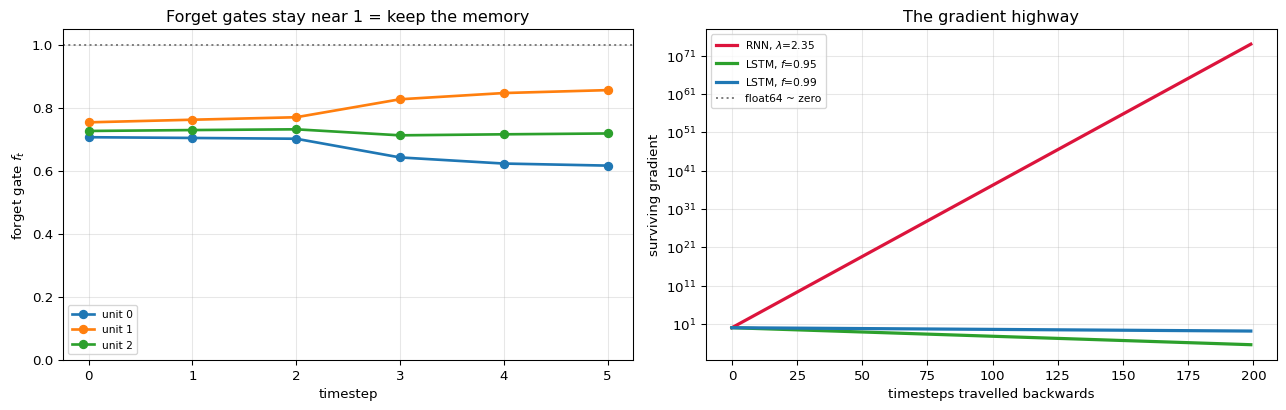

In [9]:
print("why the additive update saves the gradient\n")
print("going backwards, the cell state contributes a factor of f_t per step,")
print("not a matrix multiply:\n")
print(f"{'steps back':>12}  {'RNN: lambda^T':>16}  {'LSTM: f^T (f=0.95)':>21}  "
      f"{'LSTM: f^T (f=0.99)':>21}")
print("-" * 76)
lam = lam_actual
for Tb in (1, 5, 10, 50, 100, 500):
    print(f"{Tb:>12}  {lam**Tb:>16.4e}  {0.95**Tb:>21.4e}  {0.99**Tb:>21.4e}")
print("-" * 76)
print(f"\nAt 500 steps the RNN factor is {lam**500:.1e} - numerically zero. With a")
print(f"forget gate at 0.99 the LSTM retains {0.99**500:.3f} of the signal.")
print(f"\nThe gate is LEARNED, so the network can choose to remember (f near 1)")
print(f"or deliberately forget (f near 0) per unit and per timestep. A plain RNN")
print(f"has no such choice - Wh applies to everything, always.")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
ax = axes[0]
for j in range(D_HID):
    ax.plot(range(T), [traces[t]['f'][j] for t in range(T)], "o-", lw=2,
            label=f"unit {j}")
ax.axhline(1.0, ls=":", color="grey")
ax.set(ylim=(0, 1.05), xlabel="timestep", ylabel="forget gate $f_t$",
       title="Forget gates stay near 1 = keep the memory")
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
Tb = np.arange(0, 200)
ax.plot(Tb, lam**Tb, lw=2.4, color="crimson", label=f"RNN, $\\lambda$={lam:.2f}")
for f_, c_ in [(0.95, "tab:green"), (0.99, "tab:blue")]:
    ax.plot(Tb, f_**Tb, lw=2.4, color=c_, label=f"LSTM, $f$={f_}")
ax.axhline(1e-15, ls=":", color="grey", label="float64 ~ zero")
ax.set(yscale="log", xlabel="timesteps travelled backwards",
       ylabel="surviving gradient", title="The gradient highway")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### The GRU &mdash; the same idea, fewer parts

The GRU merges the forget and input gates into a single **update gate** $z_t$ and drops
the separate cell state:

$$\mathbf{h}_t = (1 - \mathbf{z}_t)\odot\mathbf{h}_{t-1} \;+\; \mathbf{z}_t\odot\tilde{\mathbf{h}}_t$$

The crucial property survives: $\mathbf{h}_{t-1}$ is carried by an **interpolation**, not a
matrix multiply, so the gradient path is preserved. It has 3 gate-sets instead of 4, so
about 25% fewer parameters, and in practice performs comparably.

In [10]:
print(f"{'cell':>8}  {'gate sets':>11}  {'parameters (D_in=2, D_hid=3)':>30}")
print("-" * 54)
for nm, k in [("RNN", 1), ("GRU", 3), ("LSTM", 4)]:
    p = k*(Z*D_HID + D_HID)
    print(f"{nm:>8}  {k:>11}  {p:>30}")
print("-" * 54)

print(f"\nthe carry term in each:\n")
print(f"   RNN  : h_t = tanh(Wh @ h_prev + ...)        <- matrix multiply, dangerous")
print(f"   LSTM : c_t = f * c_prev + i * c~            <- elementwise, safe")
print(f"   GRU  : h_t = (1-z) * h_prev + z * h~        <- elementwise, safe")
print(f"\nBoth gated cells replaced a matrix multiply with an elementwise gate.")
print(f"That single substitution is what made sequences of hundreds of steps")
print(f"trainable, and it is the same trick residual connections use in very")
print(f"deep feed-forward networks.")

    cell    gate sets    parameters (D_in=2, D_hid=3)
------------------------------------------------------
     RNN            1                              18
     GRU            3                              54
    LSTM            4                              72
------------------------------------------------------

the carry term in each:

   RNN  : h_t = tanh(Wh @ h_prev + ...)        <- matrix multiply, dangerous
   LSTM : c_t = f * c_prev + i * c~            <- elementwise, safe
   GRU  : h_t = (1-z) * h_prev + z * h~        <- elementwise, safe

Both gated cells replaced a matrix multiply with an elementwise gate.
That single substitution is what made sequences of hundreds of steps
trainable, and it is the same trick residual connections use in very
deep feed-forward networks.


---
# 6. Checking Against PyTorch

PyTorch's `nn.RNN` and `nn.LSTM` use the same equations with one difference in
bookkeeping: they keep **two** bias vectors (`b_ih` and `b_hh`) where the maths above uses
one, and they store weights transposed. Matching them exactly is therefore a good test
that the equations here are the real ones.

In [11]:
import torch
import torch.nn as nn

torch.set_default_dtype(torch.float64)

rnn_t = nn.RNN(D_IN, D_HID, num_layers=1, nonlinearity="tanh", batch_first=True)
with torch.no_grad():
    rnn_t.weight_ih_l0.copy_(torch.tensor(Wx.T))
    rnn_t.weight_hh_l0.copy_(torch.tensor(Wh.T))
    rnn_t.bias_ih_l0.copy_(torch.tensor(bh))
    rnn_t.bias_hh_l0.zero_()

out_t, h_t = rnn_t(torch.tensor(Xs)[None])
out_t = out_t.detach().numpy()[0]

print("hidden states, ours vs torch\n")
print(f"{'step':>6}  {'ours':>34}  {'torch':>34}")
print("-" * 80)
for t in range(T):
    print(f"{step_names[t]:>6}  {str(np.round(hs[t+1], 6)):>34}  "
          f"{str(np.round(out_t[t], 6)):>34}")
print("-" * 80)
print(f"\nMATCH: {np.allclose(hs[1:], out_t)}")
print(f"max difference: {np.abs(hs[1:] - out_t).max():.3e}")

print(f"\n\nLSTM against torch\n")
lstm_t = nn.LSTM(D_IN, D_HID, num_layers=1, batch_first=True)
# torch packs gates in the order i, f, g(candidate), o
with torch.no_grad():
    W_ih = np.vstack([Wi[D_HID:].T, Wf[D_HID:].T, Wc[D_HID:].T, Wo[D_HID:].T])
    W_hh = np.vstack([Wi[:D_HID].T, Wf[:D_HID].T, Wc[:D_HID].T, Wo[:D_HID].T])
    b_all = np.concatenate([bi, bf, bc, bo])
    lstm_t.weight_ih_l0.copy_(torch.tensor(W_ih))
    lstm_t.weight_hh_l0.copy_(torch.tensor(W_hh))
    lstm_t.bias_ih_l0.copy_(torch.tensor(b_all))
    lstm_t.bias_hh_l0.zero_()

o_l, (h_n, c_n) = lstm_t(torch.tensor(Xs)[None])
o_l = o_l.detach().numpy()[0]
ours_h = np.array([tr['h'] for tr in traces])
ours_c = np.array([tr['c'] for tr in traces])

print(f"{'step':>6}  {'our h_t':>34}  {'torch h_t':>34}")
print("-" * 80)
for t in range(T):
    print(f"{step_names[t]:>6}  {str(np.round(ours_h[t], 6)):>34}  "
          f"{str(np.round(o_l[t], 6)):>34}")
print("-" * 80)
print(f"\nhidden states MATCH: {np.allclose(ours_h, o_l)}")
print(f"final cell state MATCH: "
      f"{np.allclose(ours_c[-1], c_n.detach().numpy()[0,0])}")
print(f"   ours  c_T = {np.round(ours_c[-1], 6)}")
print(f"   torch c_T = {np.round(c_n.detach().numpy()[0,0], 6)}")
print(f"max difference: {np.abs(ours_h - o_l).max():.3e}")
print(f"\nThe gate ordering (i, f, g, o) had to be matched exactly - getting it")
print(f"wrong is a classic source of silent bugs when porting LSTM weights.")

hidden states, ours vs torch

  step                                ours                               torch
--------------------------------------------------------------------------------
    t0           [ 0.2078 -0.322   0.0372]           [ 0.2078 -0.322   0.0372]
    t1           [-0.5683 -0.4711 -0.02  ]           [-0.5683 -0.4711 -0.02  ]
    t2           [ 0.052  -0.4551  0.4274]           [ 0.052  -0.4551  0.4274]
    t3           [-0.2097 -0.9506 -0.0788]           [-0.2097 -0.9506 -0.0788]
    t4           [-0.5402 -0.9649  0.4722]           [-0.5402 -0.9649  0.4722]
    t5           [-0.2328 -0.9827  0.3371]           [-0.2328 -0.9827  0.3371]
--------------------------------------------------------------------------------

MATCH: True
max difference: 2.220e-16


LSTM against torch

  step                             our h_t                           torch h_t
--------------------------------------------------------------------------------
    t0           [ 0.0223 -0.0405 

---
# 7. Summary

| | Plain RNN | LSTM | GRU |
|---|---|---|---|
| State | $\mathbf{h}_t$ | $\mathbf{h}_t$, $\mathbf{c}_t$ | $\mathbf{h}_t$ |
| Carry | $\tanh(W_h\mathbf{h}_{t-1}+\dots)$ | $\mathbf{f}_t\odot\mathbf{c}_{t-1}+\dots$ | $(1-\mathbf{z}_t)\odot\mathbf{h}_{t-1}+\dots$ |
| Gates | none | 3 | 2 |
| Parameter sets | 1 | 4 | 3 |
| Long dependencies | poor | good | good |

**The one idea:** carry information forward through time with the *same* weights, so
sequence length stops mattering to the parameter count.

**The one flaw, and its fix:** reusing $W_h$ at every step means the backward pass
multiplies by it repeatedly, so gradients die or explode geometrically. Gated cells
replace that matrix multiply with an **elementwise gate near 1**, turning multiplication
by a matrix into multiplication by (almost) one. The same trick &mdash; an additive path that
gradients can travel along untouched &mdash; reappears as residual connections in deep
networks and as the residual stream in Transformers.

**Why Transformers displaced these:** an RNN must process step $t$ before step $t+1$, so
training cannot be parallelised across time. Attention looks at all positions at once, and
gets a path length of 1 between any two positions instead of $O(T)$ &mdash; which is where the
Autoregressive Transformer and BERT walkthroughs pick up.

**What is deliberately left out:** bidirectional and multi-layer stacking, gradient
clipping (the standard patch for the exploding case), truncated BPTT, sequence-to-sequence
with attention, and teacher forcing.